**Build a linear regression model for predicting the insurance charge**

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statistics as stats

In [3]:
df = pd.read_csv("/content/insurance data for linear regression.csv")

In [4]:
df

,age,sex,bmi,children,smoker,Claim_Amount,past_consultations,num_of_steps,Hospital_expenditure,NUmber_of_past_hospitalizations,Anual_Salary,region,charges
0,18.0,male,23.210,0.0,no,29087.54313,17.0,715428.0,4.720921e+06,0.0,5.578497e+07,southeast,1121.87390
1,18.0,male,30.140,0.0,no,39053.67437,7.0,699157.0,4.329832e+06,0.0,1.370089e+07,southeast,1131.50660
2,18.0,male,33.330,0.0,no,39023.62759,19.0,702341.0,6.884861e+06,0.0,7.352311e+07,southeast,1135.94070
3,18.0,male,33.660,0.0,no,28185.39332,11.0,700250.0,4.274774e+06,0.0,7.581968e+07,southeast,1136.39940
4,18.0,male,34.100,0.0,no,14697.85941,16.0,711584.0,3.787294e+06,0.0,2.301232e+07,southeast,1137.01100
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1333,33.0,female,35.530,0.0,yes,63142.25346,32.0,1091267.0,1.703805e+08,2.0,3.101107e+09,northwest,55135.40209
1334,31.0,female,38.095,1.0,yes,43419.95227,31.0,1107872.0,2.015152e+08,2.0,3.484216e+09,northeast,58571.07448
1335,52.0,male,34.485,3.0,yes,52458.92353,25.0,1092005.0,2.236450e+08,2.0,3.640807e+09,northwest,60021.39897
1336,45.0,male,30.360,0.0,yes,69927.51664,34.0,1106821.0,2.528924e+08,3.0,4.006359e+09,southeast,62592.87309


**EDA (Exploratory Data Analysis)**

In [5]:
#checking Info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 13 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   age                              1329 non-null   float64
 1   sex                              1338 non-null   object 
 2   bmi                              1335 non-null   float64
 3   children                         1333 non-null   float64
 4   smoker                           1338 non-null   object 
 5   Claim_Amount                     1324 non-null   float64
 6   past_consultations               1332 non-null   float64
 7   num_of_steps                     1335 non-null   float64
 8   Hospital_expenditure             1334 non-null   float64
 9   NUmber_of_past_hospitalizations  1336 non-null   float64
 10  Anual_Salary                     1332 non-null   float64
 11  region                           1338 non-null   object 
 12  charges             

In [6]:
# Check for null Values
df.isnull().sum()

,0
age,9
sex,0
bmi,3
children,5
smoker,0
Claim_Amount,14
past_consultations,6
num_of_steps,3
Hospital_expenditure,4
NUmber_of_past_hospitalizations,2


In [7]:
df.isnull().sum().sum()

np.int64(52)

In [8]:
#Check Duplicate Values

df.duplicated().sum()

#if we had to remove duplicates then use "df.drop_duplicated(inplace = True)"

np.int64(0)

# Now we have to handle the null values

We can handle null values in two ways:

1. **Dropping the null values**
2. **Filling the null values**

## When to drop null values?

* If only a **small number of rows** have null values, we can drop those rows.
* If a column has **too many null values** and is not very useful, we can drop that column.

## When to fill null values?

We can fill null values using **mean, median, mode, zero, or a suitable value**, depending on the type and meaning of the data.

### Mean

* Used for **continuous numerical data**.
* Best when the data is **normally distributed or roughly balanced**.
* Avoid using mean when there are extreme outliers.

### Median

* Used for **numerical data with very high or very low values (outliers)**.
* Example: `5, 8, 10000, 12345, 12, 600`
* Median is not affected much by extreme values.
* It is commonly used for **skewed data**.

### Mode

* Used for **categorical data**.
* Example: Gender, City, Department, etc.
* Mode means the **most frequently occurring value**.

### Filling with Zero

* We should fill with `0` **only when a missing value actually means zero or none**.
* We should not blindly replace every null value with `0`.

### Filling with "Unknown"

* For categorical data, sometimes a null value means the information is **not available**.
* In that case, we can fill it with values like `"Unknown"` or `"Not Available"`.

> **Important:** Before handling null values, we should first understand what the missing value means and how much data is missing.


In [9]:
#Now we have to handle the null values ----> by either dropping them or filling them

# Lets fill them  by either mean median or mode

# mean : if data is normally distributed (in continuous range) (continuous numeric data)

# median : if sudden high or sudden low values eg: 5, 8,10000,12345,12,600 (also called right skewed data)

# mode : for categorical kind of data

In [10]:
df.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'Claim_Amount',
       'past_consultations', 'num_of_steps', 'Hospital_expenditure',
       'NUmber_of_past_hospitalizations', 'Anual_Salary', 'region', 'charges'],
      dtype='object')

In [11]:
df.dtypes

,0
age,float64
sex,object
bmi,float64
children,float64
smoker,object
Claim_Amount,float64
past_consultations,float64
num_of_steps,float64
Hospital_expenditure,float64
NUmber_of_past_hospitalizations,float64


In [12]:
for x in df.columns:
    if df[x].dtype == "object":  # Categorical
        df[x] = df[x].fillna(df[x].mode()[0])
    else:  # Numerical
        df[x] = df[x].fillna(df[x].mean())

In [13]:
df.isnull().sum().sum()

np.int64(0)

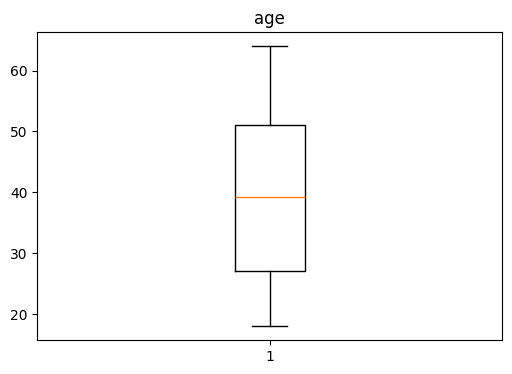

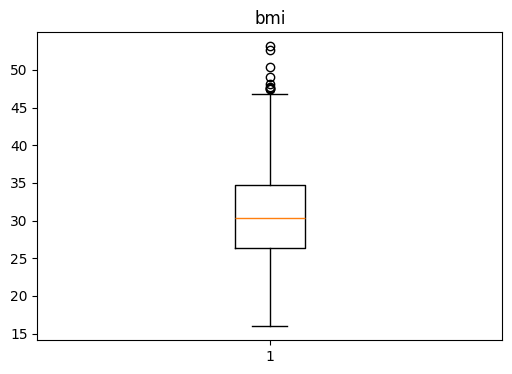

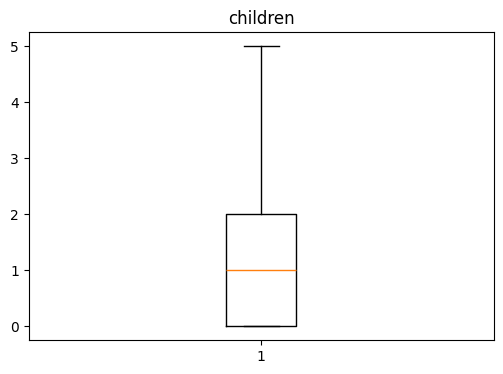

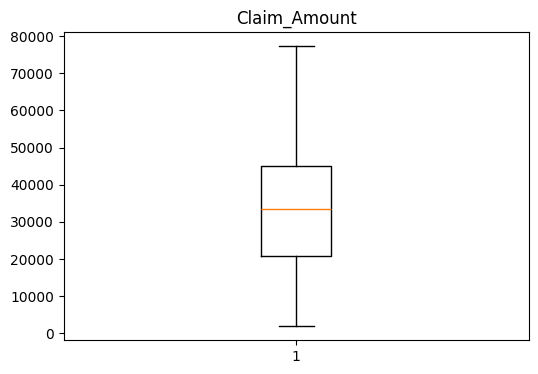

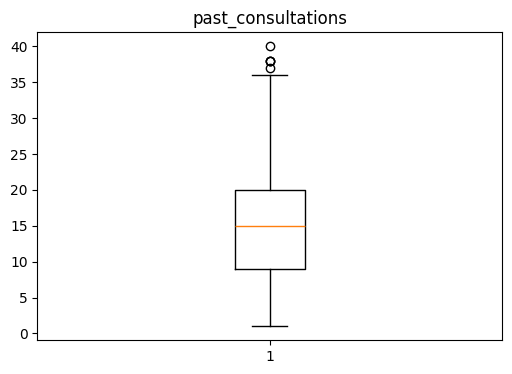

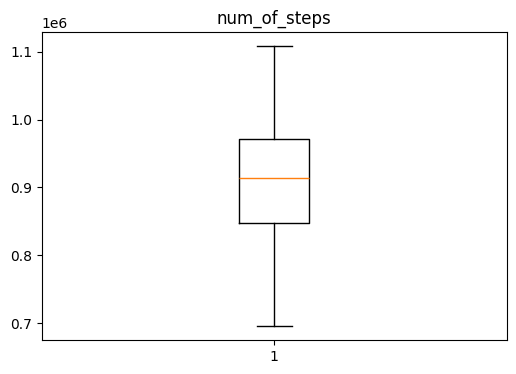

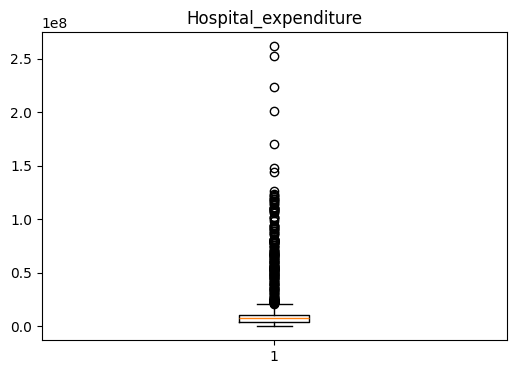

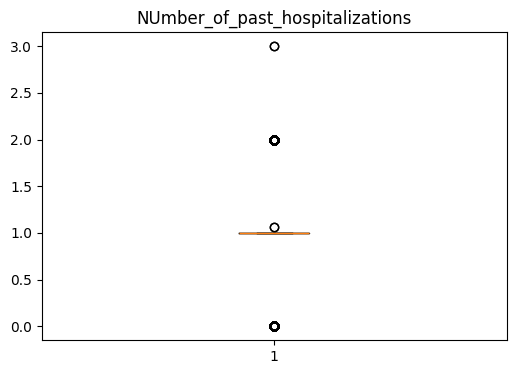

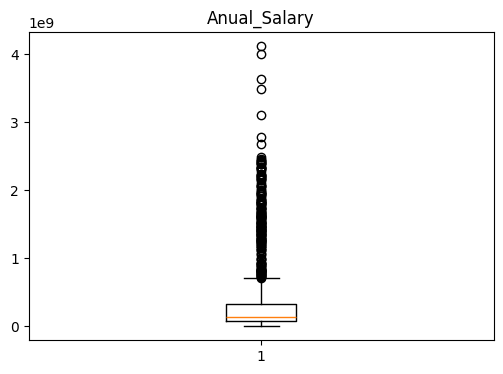

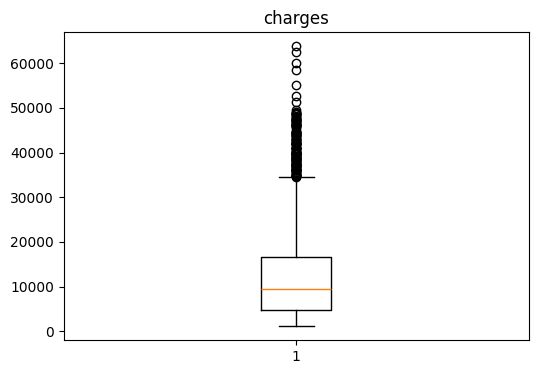

In [14]:
#Now we check for outliers
for x in df.columns:
  if df[x].dtype != "object":
    plt.figure(figsize=(6, 4))
    plt.boxplot(df[x])
    plt.title(x)
    plt.show()

In [15]:
# Using IQR method we can remove the outliers
for x in df.columns:
  if df[x].dtypes == 'object' or x == 'charges': # charges is target column
    continue

  q1 = df[x].quantile(0.25)
  q3 = df[x].quantile(0.75)
  IQR = q3 - q1

  lb = q1 - IQR*1.5
  ub = q3 + IQR*1.5
  df = df[(df[x]>=lb) & (df[x]<=ub)]


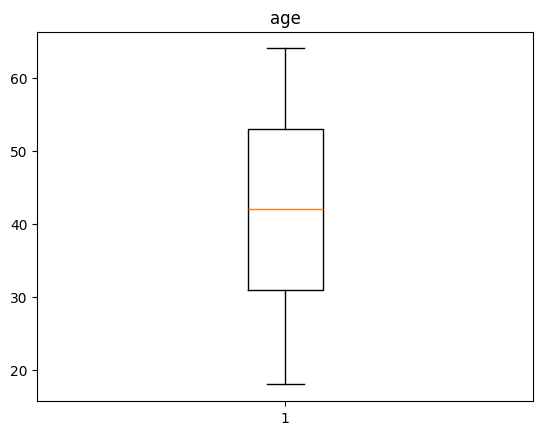

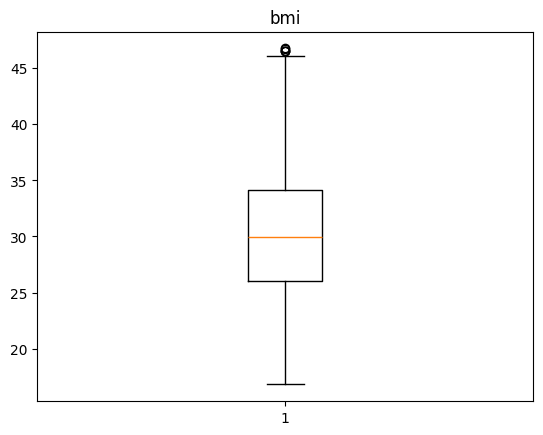

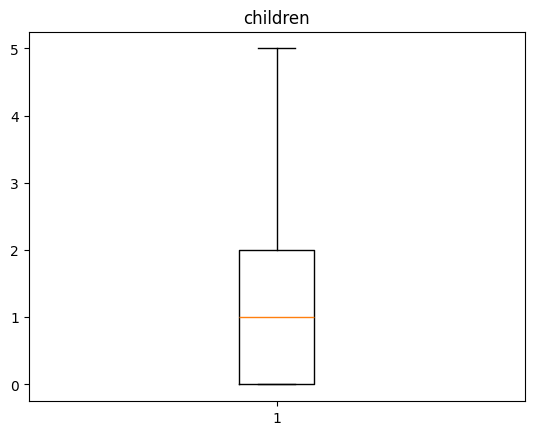

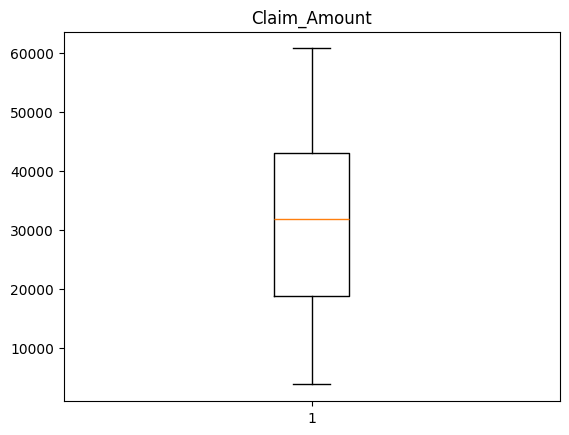

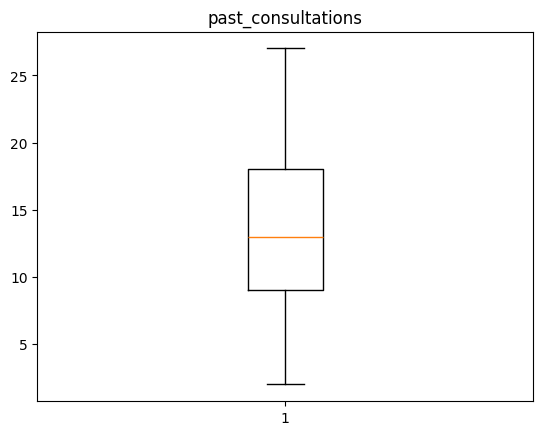

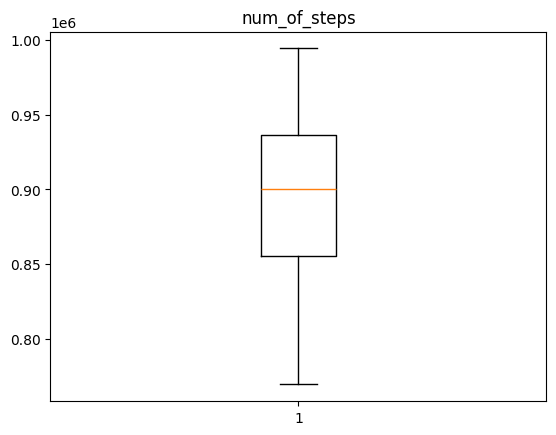

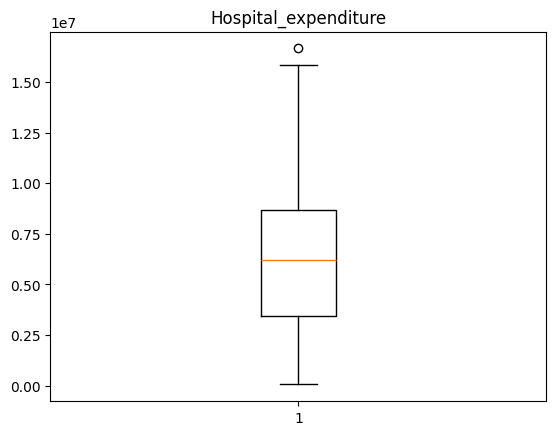

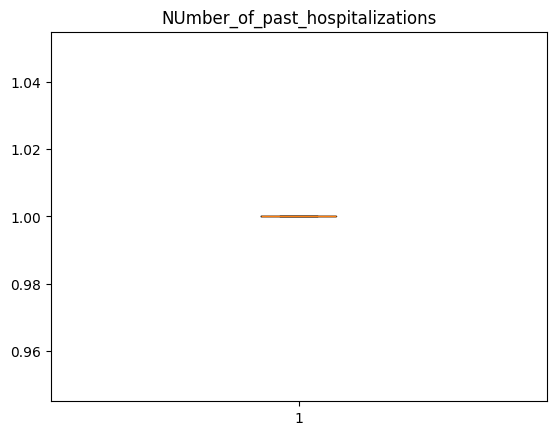

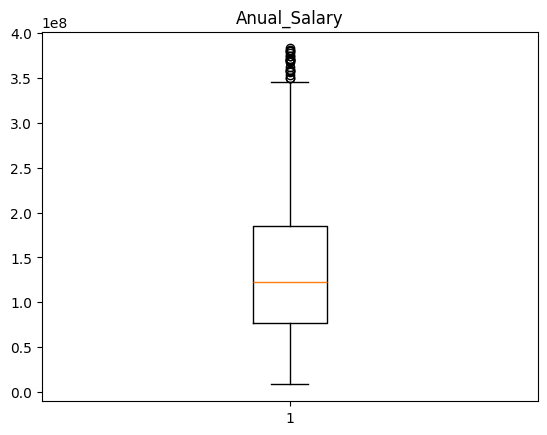

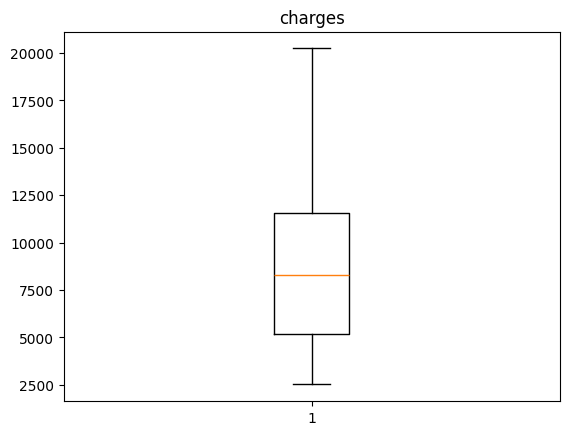

In [16]:
for x in df.columns:
  if df[x].dtype != "object":
    plt.boxplot(df[x])
    plt.title(x)
    plt.show()

In [17]:
df

,age,sex,bmi,children,smoker,Claim_Amount,past_consultations,num_of_steps,Hospital_expenditure,NUmber_of_past_hospitalizations,Anual_Salary,region,charges
151,25.0,male,27.550,0.0,no,39148.95495,10.0,780652.0,8.614147e+06,1.0,5.452601e+07,northwest,2523.16950
152,22.0,female,20.235,0.0,no,41547.52536,13.0,802627.0,2.491594e+05,1.0,1.671847e+07,northwest,2527.81865
153,25.0,male,35.625,0.0,no,39660.60193,12.0,770773.0,3.043323e+06,1.0,4.852694e+07,northwest,2534.39375
154,20.0,male,31.130,2.0,no,16032.87148,7.0,769255.0,1.599069e+06,1.0,2.441262e+07,southeast,2566.47070
155,21.0,female,17.400,1.0,no,31090.98977,21.0,778769.0,3.015365e+06,1.0,5.853579e+07,southwest,2585.26900
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1046,29.0,female,27.940,1.0,yes,51168.25474,23.0,993751.0,1.665982e+07,1.0,3.712188e+08,southeast,19107.77960
1048,31.0,male,25.900,3.0,yes,46619.40230,27.0,989387.0,1.361938e+07,1.0,3.812895e+08,southwest,19199.94400
1050,31.0,male,29.810,0.0,yes,24382.58056,21.0,973924.0,1.028991e+07,1.0,3.745310e+08,southeast,19350.36890
1062,43.0,female,20.045,2.0,yes,21596.43846,10.0,994419.0,1.083030e+07,1.0,3.696849e+08,northeast,19798.05455


**Feature Selection**

In [18]:
# VIF - (VARIANCE INFLATION FACTOR)
# MULTICOLLINEARITY - Multi + Collinearity
# multiple variables are related to each other
# It means two or more input/features are strongly related to each other (This is bad because the ML model will be confused )

In [19]:
# To remove multicolinearity from the data then we can use a Feature selection method called as VIF (Variance Inflation Factor)
# VIF helps us to deted the multi colinearity amongst the indepenedent columns
# If VIF > 5 then high multicolinearity exists ------- > remove the column
# multicolinearity is always checked for numeric data

In [20]:
# basically collect all the indepenedent numeric columns
col_list = []
for x in df.columns:
  if df[x].dtypes!='object' and x!='charges':
    col_list.append(x)

In [21]:
col_list

['age',
 'bmi',
 'children',
 'Claim_Amount',
 'past_consultations',
 'num_of_steps',
 'Hospital_expenditure',
 'NUmber_of_past_hospitalizations',
 'Anual_Salary']

In [22]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [23]:
dumm = df[col_list] # assign the collected values to dummy

In [24]:
dumm

,age,bmi,children,Claim_Amount,past_consultations,num_of_steps,Hospital_expenditure,NUmber_of_past_hospitalizations,Anual_Salary
151,25.0,27.550,0.0,39148.95495,10.0,780652.0,8.614147e+06,1.0,5.452601e+07
152,22.0,20.235,0.0,41547.52536,13.0,802627.0,2.491594e+05,1.0,1.671847e+07
153,25.0,35.625,0.0,39660.60193,12.0,770773.0,3.043323e+06,1.0,4.852694e+07
154,20.0,31.130,2.0,16032.87148,7.0,769255.0,1.599069e+06,1.0,2.441262e+07
155,21.0,17.400,1.0,31090.98977,21.0,778769.0,3.015365e+06,1.0,5.853579e+07
...,...,...,...,...,...,...,...,...,...
1046,29.0,27.940,1.0,51168.25474,23.0,993751.0,1.665982e+07,1.0,3.712188e+08
1048,31.0,25.900,3.0,46619.40230,27.0,989387.0,1.361938e+07,1.0,3.812895e+08
1050,31.0,29.810,0.0,24382.58056,21.0,973924.0,1.028991e+07,1.0,3.745310e+08
1062,43.0,20.045,2.0,21596.43846,10.0,994419.0,1.083030e+07,1.0,3.696849e+08


In [25]:
vif_data = pd.DataFrame()
vif_data['Feature'] = dumm.columns # all the numeric independent column names
vif_list = []
for i in range(len(dumm.columns)):
  vif = variance_inflation_factor(dumm.values,i)
  vif_list.append(vif)

vif_data['VIF'] = vif_list
vif_data


,Feature,VIF
0,age,2.196194
1,bmi,1.052717
2,children,1.076523
3,Claim_Amount,1.035033
4,past_consultations,1.073989
5,num_of_steps,5.882074
6,Hospital_expenditure,1.173208
7,NUmber_of_past_hospitalizations,1.000000
8,Anual_Salary,3.983678


In [26]:
# since the vif of NUmber_of_past_hospitalizations is too much then we will basically drop that column
# we basically remove columns with similar data to avoid false prediction from the model...


df = df.drop('NUmber_of_past_hospitalizations', axis = 1)

In [27]:
col_list = []
for x in df.columns:
  if df[x].dtypes!='object' and x!='charges':
    col_list.append(x)
dummy = df[col_list]
vif_data = pd.DataFrame()
vif_data['Feature'] = dummy.columns # all the numeric independent column names
vif_list = []
for i in range(len(dummy.columns)):
  vif = variance_inflation_factor(dummy.values,i)
  vif_list.append(vif)

vif_data['VIF'] = vif_list
vif_data

,Feature,VIF
0,age,2.196194
1,bmi,1.052717
2,children,1.076523
3,Claim_Amount,1.035033
4,past_consultations,1.073989
5,num_of_steps,5.882074
6,Hospital_expenditure,1.173208
7,Anual_Salary,3.983678


In [28]:
df = df.drop(columns=['num_of_steps'])

In [29]:
col_list = []
for x in df.columns:
  if df[x].dtypes!='object' and x!='charges':
    col_list.append(x)
dummy = df[col_list]
vif_data = pd.DataFrame()
vif_data['Feature'] = dummy.columns # all the numeric independent column names
vif_list = []
for i in range(len(dummy.columns)):
  vif = variance_inflation_factor(dummy.values,i)
  vif_list.append(vif)

vif_data['VIF'] = vif_list
vif_data

,Feature,VIF
0,age,1.273600
1,bmi,1.046387
2,children,1.026493
3,Claim_Amount,1.020827
4,past_consultations,1.068339
5,Hospital_expenditure,1.167493
6,Anual_Salary,1.453461


In [30]:
df = df.drop(columns=['bmi'])

In [31]:
col_list = []
for x in df.columns:
  if df[x].dtypes!='object' and x!='charges':
    col_list.append(x)
dummy = df[col_list]
vif_data = pd.DataFrame()
vif_data['Feature'] = dummy.columns # all the numeric independent column names
vif_list = []
for i in range(len(dummy.columns)):
  vif = variance_inflation_factor(dummy.values,i)
  vif_list.append(vif)

vif_data['VIF'] = vif_list
vif_data

,Feature,VIF
0,age,1.217664
1,children,1.025258
2,Claim_Amount,1.020738
3,past_consultations,1.067886
4,Hospital_expenditure,1.167057
5,Anual_Salary,1.442545


In [32]:
df = df.drop(columns=['age'])

In [33]:
col_list = []
for x in df.columns:
  if df[x].dtypes!='object' and x!='charges':
    col_list.append(x)
dummy = df[col_list]
vif_data = pd.DataFrame()
vif_data['Feature'] = dummy.columns # all the numeric independent column names
vif_list = []
for i in range(len(dummy.columns)):
  vif = variance_inflation_factor(dummy.values,i)
  vif_list.append(vif)

vif_data['VIF'] = vif_list
vif_data

,Feature,VIF
0,children,1.005061
1,Claim_Amount,1.020437
2,past_consultations,1.066508
3,Hospital_expenditure,1.165247
4,Anual_Salary,1.251012


In [34]:
# now we can perform Label Encoding
from sklearn.preprocessing import LabelEncoder
le= LabelEncoder()

for x in df.columns:
  if df[x].dtypes=='object':
    df[x] = le.fit_transform(df[x])

# **MODEL BUILDING**

In [35]:
# 1) Divide the data into x(independent variables) and y(dependent variables)

In [36]:
x = df.iloc[:,:8] # independent feature
y = df.iloc[:,-1] # dependent feature

In [37]:
# 2) divide the data into train and testing
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x,y,train_size = 0.8, random_state = 7)

In [38]:
# 3) Model bulding
from sklearn.linear_model import LinearRegression
model = LinearRegression()

In [39]:
model.fit(x_train,y_train)

LinearRegression()

In [40]:
y_pred = model.predict(x_test)

In [41]:
y_pred

array([ 5719.63163937,  8999.79622555,  8905.44570268,  7565.70106779,
       18667.38420813, 15104.05862658,  8187.55350691,  5464.34528026,
        7984.65470797,  4828.94707611, 11741.68956832,  5965.17970245,
        4787.43970567, 17617.1950153 ,  7228.25099913,  9913.60505079,
       12340.75901549, 15501.88787997,  7020.90384824,  5482.60264909,
       12442.39953136,  5444.93765054, 15682.19231586,  5788.96144747,
       10329.36949435,  6896.66143708,  8923.90386503,  4474.14912656,
       13184.00952941,  6138.84727996,  3348.2942117 ,  8546.06033809,
       16644.6327483 ,  7008.97431675,  2864.53466557,  7819.25788974,
       11794.35557882,  9582.77896032,  8257.85854267, 12064.1416739 ,
       18613.69356072,  5060.59594842, 12500.64872383,  6743.21232873,
        6015.28887067,  5519.79380567, 16755.56311875,  9269.00533432,
        9259.31380883,  4878.0358731 ,  8653.17764501, 15476.82666225,
        4573.52240732,  7886.35392991, 13545.49553767,  8562.97854189,
      

In [42]:
from sklearn.metrics import r2_score

In [43]:
r2_accuracy = r2_score(y_test, y_pred)
r2_accuracy

0.8596118266582677

In [45]:
print(x.columns.tolist())

['sex', 'children', 'smoker', 'Claim_Amount', 'past_consultations', 'Hospital_expenditure', 'Anual_Salary', 'region']


In [48]:
# Predict insurance charges for a new person

new_person = pd.DataFrame({
    'sex': ['female'],
    'children': [1],
    'smoker': ['no'],
    'Claim_Amount': [12000.0],
    'past_consultations': [4],
    'Hospital_expenditure': [15000.0],
    'Anual_Salary': [65000.0],
    'region': ['southeast']
})

# Apply the same encoding used during model training
new_person = pd.get_dummies(
    new_person,
    columns=['sex', 'smoker', 'region'],
    drop_first=True,
    dtype=int
)

# Match the exact features and order used during training
new_person = new_person.reindex(
    columns=x.columns,
    fill_value=0
)

# Predict insurance charges
predicted_charge = model.predict(new_person)

print("New Person's Details:")
display(new_person)

print(f"Predicted Insurance Charges: {predicted_charge[0]:,.2f}")

New Person's Details:


,sex,children,smoker,Claim_Amount,past_consultations,Hospital_expenditure,Anual_Salary,region
0,0,1,0,12000.0,4,15000.0,65000.0,0


Predicted Insurance Charges: 1,886.31
